# 01 · Understanding Demonstrations
**Time: 20 minutes.** Select the **Manipulation Lab (Python 3.12)** kernel, then run each cell with Shift+Enter.

## Learning Objectives
Identify observations and actions, inspect a complete human demonstration, and explain the fixed episode split.

## Background
A demonstration is a recorded sequence of observations and expert actions. An observation describes the current robot and object state; an action commands the next control step. Behavior cloning later learns this mapping. Demonstration playback restores recorded states; it is not a learned policy rollout.

## Step-by-step Instructions
### Step 1 — Start your group's session
The instructor sets `LAB_GROUP`. This cell creates a new versioned run; rerunning it starts a new assignment session and preserves previous results. Notebooks 02–04 automatically reopen this group's latest session. Restarting only their kernels does not create a new session.


> **Executed instructor solution — 2026-10-13.** Original student templates are preserved. Computation and answer-edit sessions are recorded in solution_execution.json. These answers interpret this particular run. Training and policy evaluation were each performed once in the completed run.

In [1]:
from pathlib import Path
import os, json
from IPython.display import display, Markdown, Image, Video
from manipulation_lab.common import ROOT, DATA, write_json
from manipulation_lab.notebook import workspace, command, next_stage, stage_path
from manipulation_lab.teaching import read_json, markdown_table
GROUP = os.environ.get("LAB_GROUP", "group_01")  # Use the group assigned by your instructor.
RUN = workspace(GROUP, fresh=True)
print("Dataset:", DATA)
if not DATA.is_file():
    raise FileNotFoundError("Dataset missing. From the repository root run: scripts/lab_python.sh scripts/download_dataset.py")


group_01 → /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c
Dataset: /home/jingchen/projects/manipulation_lab/data/low_dim_v15.hdf5


### Step 2 — Inspect the data contract
Expect 200 episodes and 23,207 control steps, split into 160 training, 20 validation and 20 test episodes. Entire episodes stay in one split. Only training observations determine normalization.

The policy receives **16 values**: end-effector position (3), orientation (4), gripper joint positions (2), and can pose (7). Positions are world-frame meters, with Z upward; quaternions use xyzw order. The dataset's 14-value object vector also contains relative sensors; the fixed adapter uses `object[7:14]` consistently during training and inference.

The **7 normalized actions** are three world translation increments, three axis-angle rotation increments, and one gripper command. Translation/rotation limits map to ±0.05 m / ±0.5 rad. Positive gripper commands close; negative commands open. The control frequency is 20 Hz; these indices are not acquisition timestamps.


In [2]:
from manipulation_lab.dataset import inspect
import h5py, numpy as np
info = inspect(DATA)
print("Episodes:", info["episode_count"], "Control steps:", info["total_steps"])
print("Raw observations:", info["observation_shapes"])
print("Policy observations:", info["policy_observation_shapes"])
print("Split sizes:", {k: len(v) for k, v in info["splits"].items()})
print(info["time"])


Episodes: 200 Control steps: 23207
Raw observations: {'object': [14], 'robot0_eef_pos': [3], 'robot0_eef_quat': [4], 'robot0_eef_quat_site': [4], 'robot0_gripper_qpos': [2], 'robot0_gripper_qvel': [2], 'robot0_joint_pos': [7], 'robot0_joint_pos_cos': [7], 'robot0_joint_pos_sin': [7], 'robot0_joint_vel': [7]}
Policy observations: {'robot0_eef_pos': [3], 'robot0_eef_quat': [4], 'robot0_gripper_qpos': [2], 'object': [7]}
Split sizes: {'train': 160, 'validation': 20, 'test': 20}
{'timestamps': 'missing unless listed per episode', 'index': 'control step', 'control_hz': 20}


### Step 3 — Play and inspect one demonstration
Choose `EPISODE` from `demo_0` to `demo_199`. Record one example of how the gripper command relates to object motion. The scatter plot shows the **first state of each demonstration**, not every trajectory state.


Step 0 end effector (world m): [-0.06557359 -0.08585878  0.99297061] can (world m): [ 0.12372491 -0.20150121  0.86      ] normalized action: [ 0.057      -0.006      -0.033      -0.00545421  0.05305817 -0.02445366
 -1.        ]
Step 59 end effector (world m): [ 0.11733838 -0.20721327  0.87153548] can (world m): [ 0.12483867 -0.2035444   0.86474429] normalized action: [-0.044       0.331       0.243      -0.01277328 -0.00208974 -0.00480722
  1.        ]
Step 117 end effector (world m): [0.19102554 0.32896586 1.01427958] can (world m): [0.20088983 0.34891714 0.86017171] normalized action: [-0.184      -0.268       0.151       0.0217144   0.01301221 -0.02317772
 -1.        ]
Running replay_demo.py


[robosuite WARNING] No private macro file found! (macros.py:53)
[robosuite WARNING] It is recommended to use a private macro file (macros.py:54)
[robosuite WARNING] To setup, run: python /home/jingchen/projects/manipulation_lab/third_party/robosuite/robosuite/scripts/setup_macros.py (macros.py:55)


[robosuite WARNING] Could not import robosuite_models. Some robots may not be available. If you want to use these robots, please install robosuite_models from source (https://github.com/ARISE-Initiative/robosuite_models) or through pip install. (__init__.py:30)
[robosuite WARNING] Could not load the mink-based whole-body IK. Make sure you install related import properly, otherwise you will not be able to use the default IK controller setting for GR1 robot. (__init__.py:40)



============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_eef_quat', 'robot0_gripper_qpos', 'robot0_eef_pos', 'object']
Created environment with name PickPlaceCan
Action size is 7


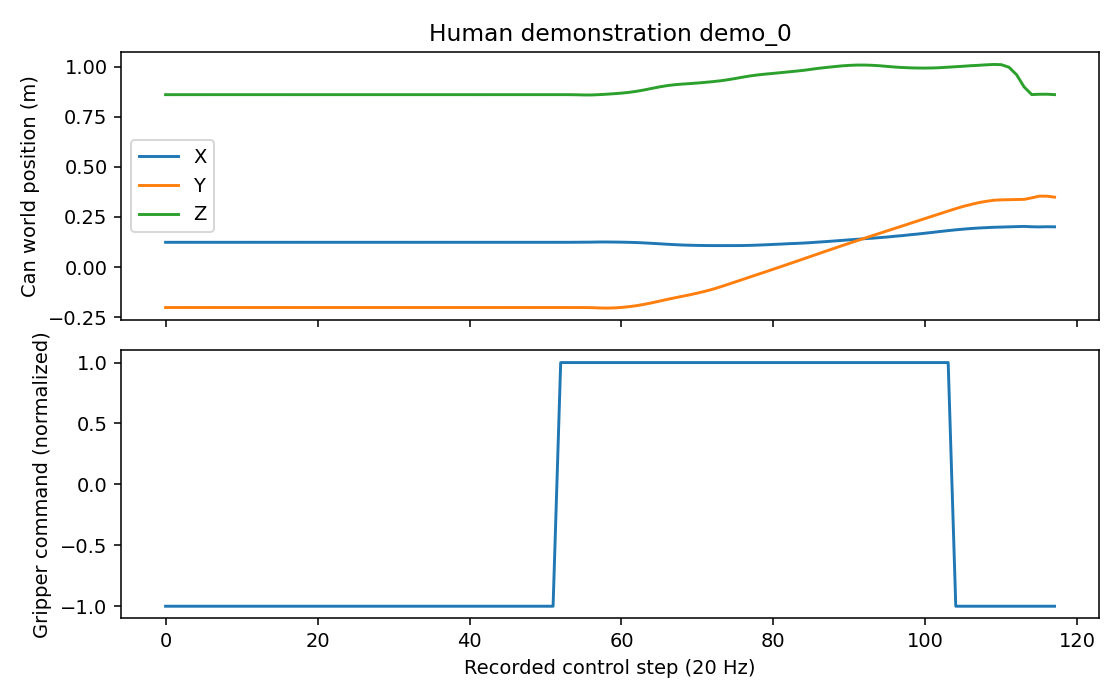

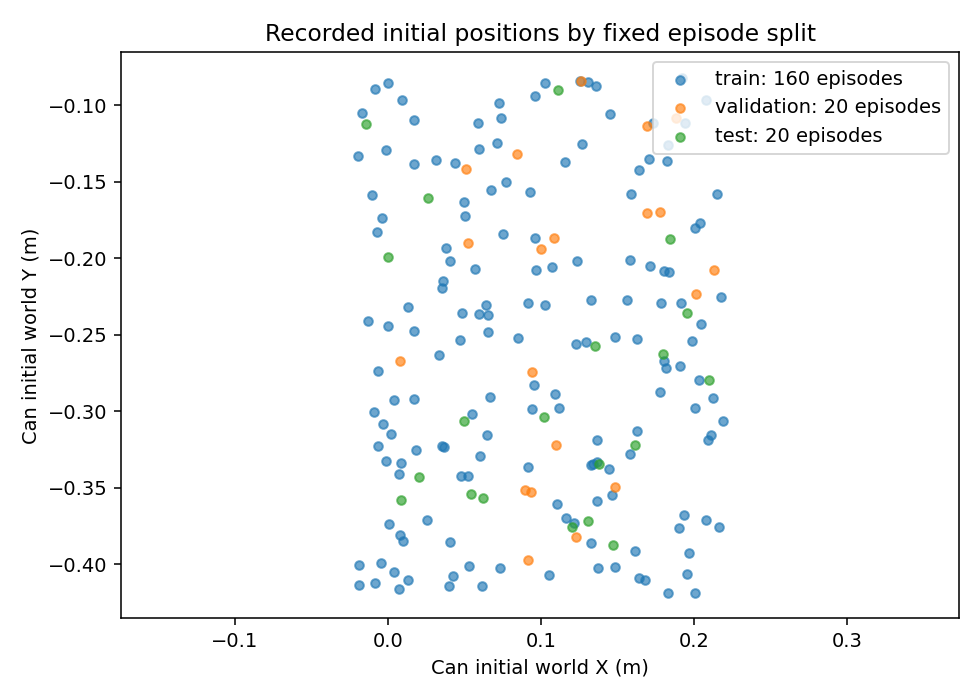

Saved video, figures and data inspection: /home/jingchen/projects/manipulation_lab/outputs/solutions_20261013_v2/runs/group_01/20261013T051828Z_5a8ae81c/demonstration_051829_cc67c5


In [3]:
EPISODE = "demo_0"
with h5py.File(DATA, "r") as f:
    d = f["data"][EPISODE]
    expert_actions = d["actions"][:]
    world_position = d["obs/object"][:, 7:10]
    eef_position = d["obs/robot0_eef_pos"][:]
    for step in [0, len(expert_actions) // 2, len(expert_actions) - 1]:
        print("Step", step, "end effector (world m):", eef_position[step],
              "can (world m):", world_position[step], "normalized action:", expert_actions[step])
DEMO = next_stage(RUN, "demonstration")
command("replay_demo.py", "--dataset", DATA, "--episode", EPISODE, "--output", DEMO)
from manipulation_lab.visualization import demonstration_figures
demonstration_figures(info, EPISODE, world_position, expert_actions, DEMO)
write_json(DEMO / "dataset_inspection.json", info)
display(Video(str(DEMO / "demonstration.mp4"), embed=True))
for filename in ["demonstration_signals.png", "demonstration_positions.png"]:
    display(Image(filename=str(DEMO / filename)))
print("Saved video, figures and data inspection:", DEMO)


## Expected Outputs
A real demonstration video, separate position and action plots, a split-specific initial-position plot, and a dataset inspection JSON. All are saved in your run directory.

## Questions for Students
**Q1. What observations and actions are used in this task?** State the coordinate frame, dimensions and units. Also explain why full trajectories are more informative than successful final images. Fill the strings below in your own words and rerun this cell to save them.


In [2]:
Q1 = 'The policy observes 16 values: end-effector world position (3), end-effector xyzw quaternion (4), two finger joint positions (2), and can world position plus xyzw quaternion (7). Positions and finger joint displacements are in meters, with world Z upward; quaternion components are dimensionless. The adapter takes object[7:14] from the raw 14-value object vector in both training and inference. The seven normalized actions are world translation increments (3), axis-angle rotation increments (3), and one gripper command (1). Commands lie in [-1,1]; translation and rotation scale to controller limits of +/-0.05 m and +/-0.5 rad. A positive gripper command closes and a negative command opens; it is not a measured opening in meters. Two finger joints give two observation values but only one independent open/close command. The control frequency is 20 Hz, so one interval is 0.05 s; step indices are not acquisition timestamps.'
TRAJECTORY_REFLECTION = 'demo_0 contains 118 recorded steps. Its first positive gripper command is action index 52; the can height ranges from 0.85851 to 1.01071 m over the recorded observations. A final image cannot reveal approach, closure, lift, transport and release ordering or provide the aligned observation/expert-action pairs needed for training. The trajectory does. A commanded closure alone does not prove secure grasping. Demonstration playback restores recorded simulator states and is distinct from a learned-policy rollout. The 160/20/20 split keeps complete episodes together, reducing leakage of adjacent correlated states; only the 160 training episodes supply normalization statistics.'
write_json(RUN / "demonstration_analysis.json", {
    "episode": EPISODE, "length": len(expert_actions), "source": "human_demonstration",
    "observations": info["policy_observation_shapes"], "action_dim": 7,
    "q1": Q1, "q2": TRAJECTORY_REFLECTION,
    "answers_complete": bool(Q1.strip() and TRAJECTORY_REFLECTION.strip()),
    "dataset_sha256": info["dataset_sha256"]})
print("Saved answers. Blank answers keep the final report in DRAFT status.")

display(Markdown("**Q1 — Instructor solution**\n\n" + Q1))
display(Markdown("**TRAJECTORY_REFLECTION — Instructor solution**\n\n" + TRAJECTORY_REFLECTION))

Saved answers. Blank answers keep the final report in DRAFT status.


**Q1 — Instructor solution**

The policy observes 16 values: end-effector world position (3), end-effector xyzw quaternion (4), two finger joint positions (2), and can world position plus xyzw quaternion (7). Positions and finger joint displacements are in meters, with world Z upward; quaternion components are dimensionless. The adapter takes object[7:14] from the raw 14-value object vector in both training and inference. The seven normalized actions are world translation increments (3), axis-angle rotation increments (3), and one gripper command (1). Commands lie in [-1,1]; translation and rotation scale to controller limits of +/-0.05 m and +/-0.5 rad. A positive gripper command closes and a negative command opens; it is not a measured opening in meters. Two finger joints give two observation values but only one independent open/close command. The control frequency is 20 Hz, so one interval is 0.05 s; step indices are not acquisition timestamps.

**TRAJECTORY_REFLECTION — Instructor solution**

demo_0 contains 118 recorded steps. Its first positive gripper command is action index 52; the can height ranges from 0.85851 to 1.01071 m over the recorded observations. A final image cannot reveal approach, closure, lift, transport and release ordering or provide the aligned observation/expert-action pairs needed for training. The trajectory does. A commanded closure alone does not prove secure grasping. Demonstration playback restores recorded simulator states and is distinct from a learned-policy rollout. The 160/20/20 split keeps complete episodes together, reducing leakage of adjacent correlated states; only the 160 training episodes supply normalization statistics.

## Completion Checklist
- [x] I played a recorded human demonstration and identified the object interaction.
- [x] I can distinguish observations, normalized commands and physical positions.
- [x] I inspected the fixed split and initial-position distribution.
- [x] I saved Q1 and the trajectory reflection. Continue to Notebook 02 using the same group.
